# 03 · A company built from rules

**The question this step answers:** how is one fake company's chart of accounts made? A rule-based company takes about 40 groups of the standard chart, writes them the way that company would (its language, the noise rules of notebook 02), adds a few sub-accounts and gives every account its own code. Because the generator picked each group itself, every account comes with its **right answer for free**.

**Where it sits in the pipeline:** after the noise rules (notebook 02). Two thirds of all accounts are made this way; the rest are written by an LLM (notebook 04).

**The code:** `src/d1/datagen/rule_charts.py` → `generate_rule_company(company_id, split, industry, language, chart, n_accounts, rng, code_scheme)`.

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

from d1.datagen.rule_charts import BASE_SHARE, BILINGUAL_P, SUB_QUALIFIERS, generate_rule_company, legacy_codes
from d1.datagen.schema import read_jsonl
from d1.datagen.splits import _company_rng, company_plan

split_cfg = config.data.splits["test"]
plan = company_plan("test", split_cfg, config.data.industries, config.data.languages)
saved = [r for r in read_jsonl(config.data.generated_dir / "test.jsonl")]

## 1. The company we follow

The split plan (notebook 05) says what each company must be. We follow the first test company:

In [2]:
spec = plan[0]
display(pd.Series(spec.model_dump(), name=spec.company_id).to_frame())
print(f"random seed for this company: {split_cfg.seed} * 1000 + {spec.index} = {split_cfg.seed * 1000 + spec.index}")

,test-c000
company_id,test-c000
split,test
industry,software
language,nl
source,rules
code_scheme,pcmn
index,0
n_accounts,50


random seed for this company: 2002 * 1000 + 0 = 2002000


## 2. What the generator does, step by step

1. **Pick the groups.** 80% of the accounts (40 of 50) are each a different standard group, drawn at random from the 190.
2. **Write each group's name** in the company's language. A *mixed* company writes each group in Dutch, French or English, and sometimes as a bilingual "nl / fr" label (30% of its groups).
3. **Run each name through the noise rules** (notebook 02), which record a tag for every change.
4. **Add sub-accounts** for the other 20% (10 of 50). A sub-account reuses its parent's name plus a qualifier ("- Gent", "- project A"), as real charts split one group per site or project.
5. **Give every account a code**, in one of two schemes:
   - **pcmn:** the company follows the Belgian numbering, so the code starts with the right group ("440000", "440001"). Realistic, but it gives the answer away.
   - **legacy:** the company uses its own old numbering, sequential 4-digit codes that **never** start with the right group. The mapper then has to read the name.

Running it for our company, with the seed the plan gives it:

In [3]:
rows = generate_rule_company(spec.company_id, "test", spec.industry, spec.language, chart, spec.n_accounts,
                             _company_rng(split_cfg, spec), code_scheme=spec.code_scheme)
company = pd.DataFrame([{
    "code": r.code, "name (as the company writes it)": r.name, "right group": r.target_code,
    "official name": by_code[r.target_code].name(r.language), "tags": ", ".join(r.noise),
} for r in rows])
display(company.head(15))
# overlaps_dev is set later, when the split is built (notebook 05), so it is left out of the comparison.
def fields(r):
    return r.model_dump(exclude={"overlaps_dev"})
same = [fields(r) for r in rows] == [fields(r) for r in saved if r.company_id == spec.company_id]
print(f"{len(rows)} accounts, {company['right group'].nunique()} different groups; identical to the saved test split: {same}")

,code,name (as the company writes it),right group,official name,tags
0,121000,Herwaarderingsmeerwaarden op materiële vaste activa,121,Herwaarderingsmeerwaarden op materiële vaste activa,
1,132000,Belastingvrije reserves,132,Belastingvrije reserves,
2,160000,VOORZIENINGEN VOOR PENSIOENEN EN SOORTGELIJKE VERPLICHTINGEN,160,Voorzieningen voor pensioenen en soortgelijke verplichtingen,case
3,164000,Voorz. voor overige risico's en kosten,164,Voorzieningen voor overige risico's en kosten,abbreviation
4,164001,Voorz. voor overige risico's en kosten - Gent,164,Voorzieningen voor overige risico's en kosten,"abbreviation, sub_account"
5,168000,uitgestelde bel.,168,Uitgestelde belastingen,"abbreviation, case"
6,212000,Goodwill,212,Goodwill,
7,220000,terreinen,220,Terreinen,case
8,222000,Bebouwde terreinen,222,Bebouwde terreinen,
9,223000,Overige zakelijke rechten op onroerende goederen,223,Overige zakelijke rechten op onroerende goederen,


50 accounts, 40 different groups; identical to the saved test split: True


Reading the table: each row is one account. **right group** is the answer key. Compare **name** with **official name** to see what the noise did. The last line checks that running the generator again gives exactly the accounts saved in `data/generated/test.jsonl`: same seed, same company, every time. The one field left out, `overlaps_dev`, is added afterwards, when the test split is compared with train and dev (notebook 05).

## 3. Sub-accounts

The accounts that share a group: the first one is the group's main account, the others add a qualifier. All of them have the same right answer.

In [4]:
subs = company[company["tags"].str.contains("sub_account")]["right group"].unique()
display(company[company["right group"].isin(subs[:3])][["code", "name (as the company writes it)", "right group", "tags"]])

,code,name (as the company writes it),right group,tags
3,164000,Voorz. voor overige risico's en kosten,164,abbreviation
4,164001,Voorz. voor overige risico's en kosten - Gent,164,"abbreviation, sub_account"
10,250000,Terreinen en gebouwen in leasing of op grond van een soortgelijk recht,250,
11,250001,Terreinen en gebouwen in leasing of op grond van een soortgelijk recht - Antwerpen,250,sub_account
14,319000,Hulpstoffen - Geboekte waardeverm. (-),319,abbreviation
15,319001,Hulpstoffen - Geboekte waardeverm. (-) - Antwerpen,319,"abbreviation, sub_account"


## 4. The two code schemes, side by side

The same kind of company with each scheme. With **pcmn**, the first three digits of the code *are* the answer. With **legacy**, the codes run 4-digit and sequential, and the generator skips any code that would start with the right group, so the code never leaks the answer.

In [5]:
legacy_spec = next(s for s in plan if s.source == "rules" and s.code_scheme == "legacy")
legacy_rows = [r for r in saved if r.company_id == legacy_spec.company_id]
side = pd.DataFrame({
    "pcmn: code": [r.code for r in rows[:8]], "pcmn: right group": [r.target_code for r in rows[:8]],
    "legacy: code": [r.code for r in legacy_rows[:8]], "legacy: right group": [r.target_code for r in legacy_rows[:8]],
})
display(side)

all_rules = [r for split in ["train", "dev", "test"] for r in read_jsonl(config.data.generated_dir / f"{split}.jsonl") if r.code_scheme == "legacy"]
leaks = sum(r.code.startswith(r.target_code) for r in all_rules)
print(f"legacy-coded accounts in all three splits (rule-based and LLM-written): {len(all_rules)}; codes that start with the right group: {leaks}")

,pcmn: code,pcmn: right group,legacy: code,legacy: right group
0,121000,121,4880,120
1,132000,132,4890,121
2,160000,160,4900,168
3,164000,164,4910,173
4,164001,164,4920,176
5,168000,168,4930,222
6,212000,212,4940,291
7,220000,220,4950,350


legacy-coded accounts in all three splits (rule-based and LLM-written): 7999; codes that start with the right group: 0


## 5. Mixed companies

A *mixed* company, like many in Brussels, writes some groups in Dutch, some in French, some in English, and some as bilingual labels:

In [6]:
mixed_spec = next(s for s in plan if s.source == "rules" and s.language == "mixed")
mixed_rows = [r for r in saved if r.company_id == mixed_spec.company_id]
display(pd.DataFrame([{"name": r.name, "right group": r.target_code, "tags": ", ".join(r.noise)} for r in mixed_rows[:10]]))

,name,right group,tags
0,Herwaarderingsmeerwaarden op immat. vaste activa / Plus-values de réévaluation sur imm...,120,"bilingual, abbreviation"
1,herwaarderingsmeerwaarden op financiële vaste activa,122,case
2,herwaarderingsmeerwaarden op financiële vaste activa - Brussel,122,"case, sub_account"
3,belastingvrije reserves / réserves immunisées,132,"bilingual, case"
4,Voorzieningen voor grote herstellings- en onderhoudswerken,162,
5,niet-achtergestelde obligatieleningen (> 1 jaar) / emprunts obligataires non subordonn...,171,"bilingual, case, accents_stripped"
6,niet-achtergestelde obligatieleningen (> 1 jaar) / emprunts obligataires non subordonn...,171,"bilingual, case, accents_stripped, sub_account"
7,niet-achtergestelde obligatieleningen (> 1 jaar) / emprunts obligataires non subordonn...,171,"bilingual, case, accents_stripped, sub_account"
8,Leasing and Other Siimilar Obligations (> 1 Year),172,typo
9,Herstructureringskosten / Frais de restructuation,204,"bilingual, typo"


## 6. Across all rule-based companies: is every group covered?

Every group should appear often enough in training, or a model can't learn it. Across the 200 rule-based training companies, how many accounts each of the 190 groups gets:

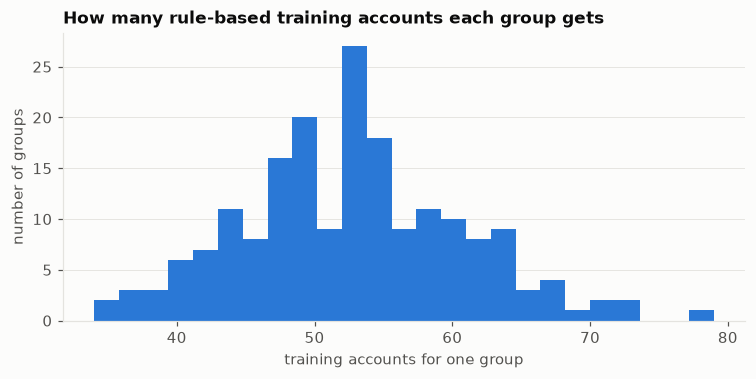

fewest: 34 accounts (group 319), most: 79, median 52; groups never seen: 0


In [7]:
train_rules = [r for r in read_jsonl(config.data.generated_dir / "train.jsonl") if r.source == "rules"]
per_group = pd.Series(Counter(r.target_code for r in train_rules)).reindex([a.code for a in chart], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(per_group.values, bins=25, color=SINGLE)
ax.set_xlabel("training accounts for one group")
ax.set_ylabel("number of groups")
ax.grid(axis="x", visible=False)
ax.set_title("How many rule-based training accounts each group gets")
plt.show()
print(f"fewest: {per_group.min()} accounts (group {per_group.idxmin()}), most: {per_group.max()}, median {int(per_group.median())}; groups never seen: {(per_group == 0).sum()}")

## 7. What is *not* happening

- **No industry logic.** A rule-based software company can have a "Raw materials" account. The industry is recorded, but only the LLM-written companies use it to choose realistic accounts.
- **No new wording.** Every name is a standard name with noise on top. That's why rule-based accounts are easy for the embeddings (99% on the shortlist in notebook 08), and why the LLM companies exist.
- **No hand labelling needed.** The right group is known by construction. Notebook 06 spot-checks 50 test rows to confirm it.